In [1]:
# 08 - Ensemble learning: merging the MODELS themselves (soft vote, like the "Ensemble Learning" chapter of the course)
#
# Soft vote = the mean of the probabilities of "abnormal" given by several models; more than 0.5 -> abnormal.
# Different models make different mistakes: the mean can be better than each model alone.
# The probabilities come from the notebooks 03, 04, 06 and 07 (files probs_<model>.data):
#   - VALIDATION: the "out-of-fold" probabilities: each wav of the 80% train part got its probability from the fold
#     where it was in the validation third (the same 3 folds for all the models) -> no model saw the wav it scored
#   - TEST: the probabilities of the final models on the 20% test set
# Nothing is learned on the test set: the combination is chosen with the validation results only (the merge rule:
# a higher recall, or a higher F1 without losing more than 0.01 of recall), then it is tested ONCE.
# The SVM gives a class and a distance to its border, not a probability: it is not in the vote.
# MLflow (experiment audio_benchmark_final): run "ensemble". It enters the benchmark (notebook 05) as one more model;
# in the audio engine it is just the mean of the ONNX outputs that the engine already computes (no new model file).

In [2]:
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

import mlflow

In [3]:
project_folder = "D:/MLOps_Project/"
plots_folder = "D:/MLOps_Project/models plots/"


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


# the probabilities saved by each notebook (the same wavs in the same order: checked)
MODELS = ["CNN", "ResNet50", "TransformerCNN", "DecisionTree"]
probs = {}
for model in MODELS:
    probs[model] = load_data(project_folder + "probs_" + model.lower() + ".data")
    assert probs[model]["train_names"] == probs["CNN"]["train_names"], model + ": not the same train wavs"
    assert probs[model]["test_names"] == probs["CNN"]["test_names"], model + ": not the same test wavs"
    assert probs[model]["fold"] == probs["CNN"]["fold"], model + ": not the same 3 folds"

y_train = np.array(probs["CNN"]["train_y"])
y_test = np.array(probs["CNN"]["test_y"])
fold_of = np.array(probs["CNN"]["fold"])          # 1, 2 or 3: the fold where each train wav was in validation
print("train (80%):", len(y_train), "wavs | test (20%):", len(y_test), "wavs | models:", MODELS)

train (80%): 2944 wavs | test (20%): 737 wavs | models: ['CNN', 'ResNet50', 'TransformerCNN', 'DecisionTree']


In [4]:
# ==================== The combinations, on the validation (out-of-fold) probabilities ====================
def metrics_of(y_true, probability):
    y_pred = (probability > 0.5).astype(int)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, probability)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred), "f1": f1_score(y_true, y_pred),
            "auc": auc(false_positive_rate, true_positive_rate)}


def mean_probability(members, part):
    # part = "oof_prob" (validation) or "test_prob" (test)
    total = np.zeros(len(probs["CNN"][part]))
    for model in members:
        total = total + np.array(probs[model][part])
    return total / len(members)


def fold_results(probability):
    rows = []
    for fold in [1, 2, 3]:
        in_fold = fold_of == fold
        rows.append(dict(fold=fold, **metrics_of(y_train[in_fold], probability[in_fold])))
    return rows


metrics = ["accuracy", "precision", "recall", "f1", "auc"]
combinations = [["CNN"], ["CNN", "ResNet50"], ["CNN", "TransformerCNN"], ["CNN", "ResNet50", "TransformerCNN"],
                ["CNN", "ResNet50", "TransformerCNN", "DecisionTree"]]
table = []
for members in combinations:
    rows = pd.DataFrame(fold_results(mean_probability(members, "oof_prob")))
    line = {"members": " + ".join(members)}
    for metric in metrics:
        line[metric] = round(rows[metric].mean(), 3)     # the mean of the 3 folds, like the other models
    table.append(line)
table = pd.DataFrame(table)
ipd.display(table)


def replaces(candidate, current):
    # the merge rule: a higher recall, or a higher F1 without losing more than 0.01 of recall
    if candidate["recall"] > current["recall"]:
        return True
    return candidate["f1"] > current["f1"] and candidate["recall"] >= current["recall"] - 0.01


# the first line is the CNN alone (for comparison): the ensemble is chosen among the real combinations (2+ models)
best = 1
for i in range(2, len(table)):
    if replaces(table.loc[i], table.loc[best]):
        best = i
members = combinations[best]
print("Chosen ensemble:", " + ".join(members))
print("(the CNN alone is in the first line to compare; the benchmark of notebook 05 decides the official model)")

,members,accuracy,precision,recall,f1,auc
0,CNN,0.750,0.472,0.938,0.628,0.905
1,CNN + ResNet50,0.861,0.645,0.847,0.732,0.942
2,CNN + TransformerCNN,0.797,0.553,0.867,0.660,0.925
3,CNN + ResNet50 + TransformerCNN,0.841,0.616,0.863,0.712,0.944
4,CNN + ResNet50 + TransformerCNN + DecisionTree,0.843,0.619,0.858,0.714,0.941


Chosen ensemble: CNN + ResNet50 + TransformerCNN + DecisionTree
(the CNN alone is in the first line to compare; the benchmark of notebook 05 decides the official model)


,fold,accuracy,precision,recall,f1,auc
0,1,0.885,0.729,0.796,0.761,0.941
1,2,0.811,0.551,0.901,0.684,0.941
2,3,0.834,0.577,0.878,0.696,0.942


Mean of the 3 folds (validation):
accuracy     0.843
precision    0.619
recall       0.858
f1           0.714
auc          0.941
dtype: float64


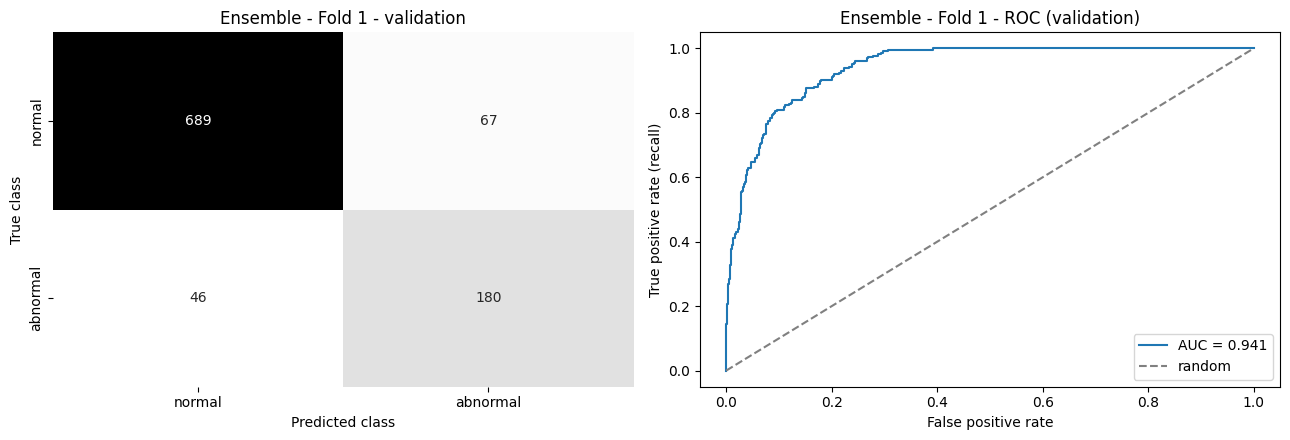

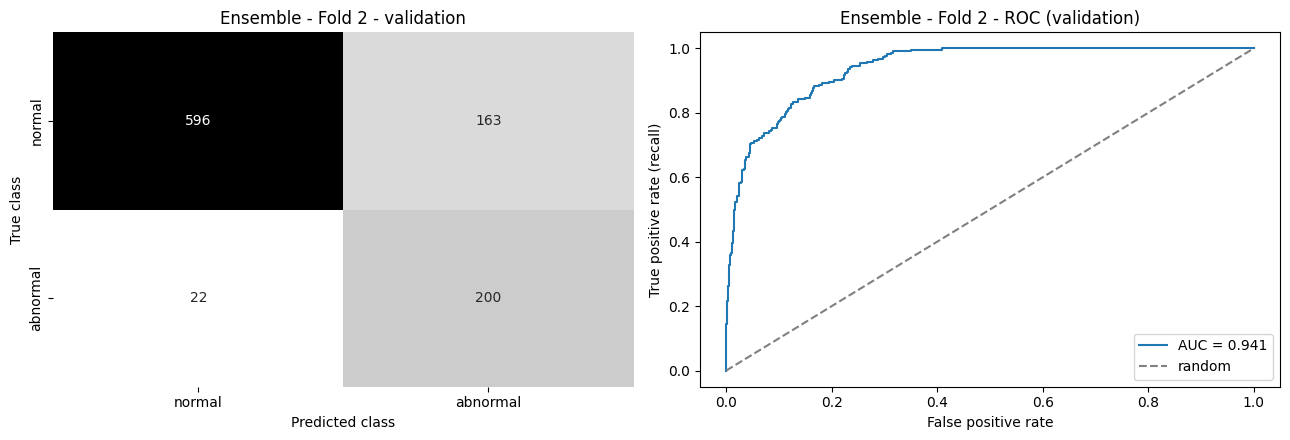

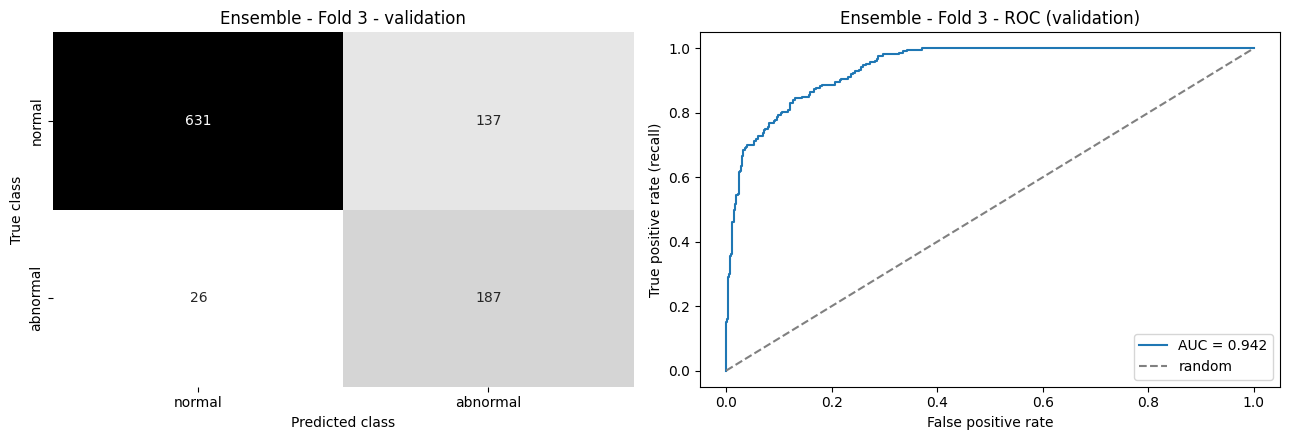

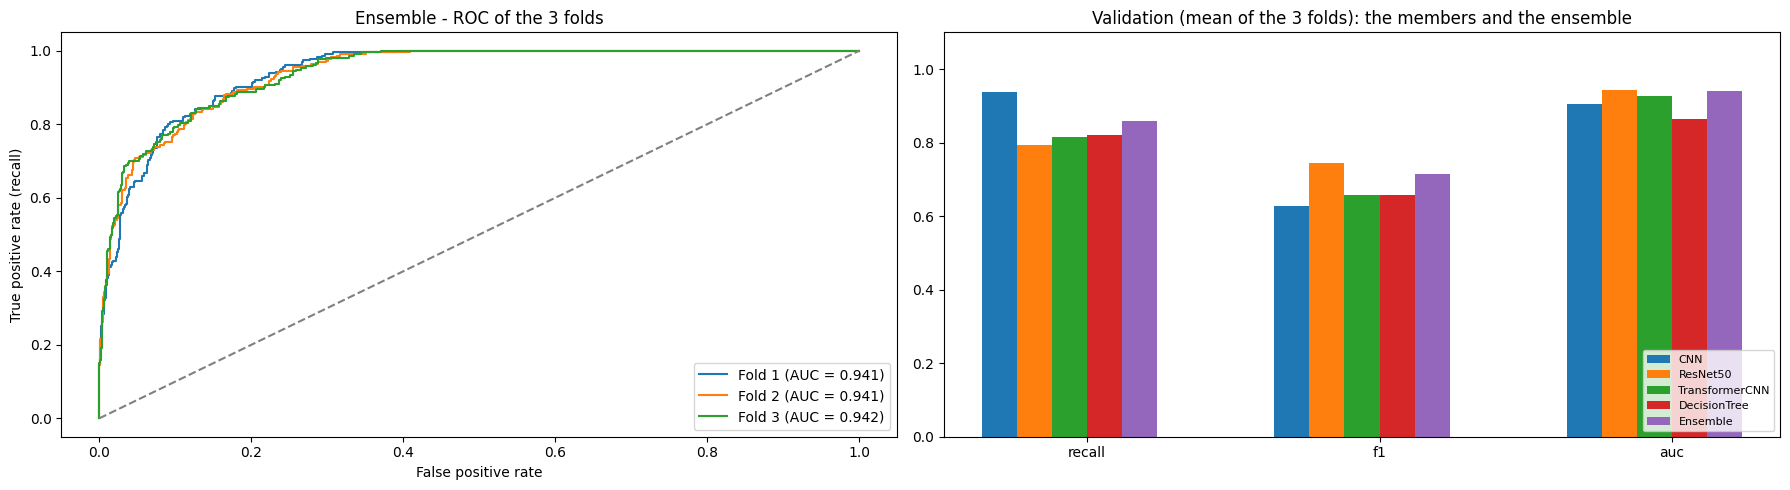

In [5]:
def PlotConfusionMatrix(cm, title):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greys", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


def plot_roc(y_true, y_score, title):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, y_score)
    area = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label="AUC = {:.3f}".format(area))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="random")
    plt.title(title)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.legend(loc="lower right")


# ==================== VALIDATION of the chosen ensemble: the 3 folds ====================
oof = mean_probability(members, "oof_prob")
results = fold_results(oof)
fold_table = pd.DataFrame(results)
ipd.display(fold_table.round(3))
print("Mean of the 3 folds (validation):")
print(fold_table[metrics].mean().round(3))

for fold in [1, 2, 3]:
    in_fold = fold_of == fold
    plt.figure(figsize=(13, 4.5))
    plt.subplot(1, 2, 1)
    PlotConfusionMatrix(confusion_matrix(y_train[in_fold], (oof[in_fold] > 0.5).astype(int)),
                        "Ensemble - Fold " + str(fold) + " - validation")
    plt.subplot(1, 2, 2)
    plot_roc(y_train[in_fold], oof[in_fold], "Ensemble - Fold " + str(fold) + " - ROC (validation)")
    plt.tight_layout()
    plt.savefig(plots_folder + "tp10_ensemble_val_fold" + str(fold) + ".png")
    plt.show()

# summary: the ROC of the 3 folds + the metrics of the members and of the ensemble (validation)
plt.figure(figsize=(18, 5))
plt.subplot(1, 2, 1)
for fold in [1, 2, 3]:
    in_fold = fold_of == fold
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_train[in_fold], oof[in_fold])
    plt.plot(false_positive_rate, true_positive_rate,
             label="Fold " + str(fold) + " (AUC = {:.3f})".format(results[fold - 1]["auc"]))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("Ensemble - ROC of the 3 folds")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")
plt.subplot(1, 2, 2)
names = members + ["Ensemble"]
values = []
for model in members:
    values.append(pd.DataFrame(fold_results(np.array(probs[model]["oof_prob"])))[["recall", "f1", "auc"]].mean())
values.append(fold_table[["recall", "f1", "auc"]].mean())
x = np.arange(3)
for i in range(len(names)):
    plt.bar(x - 0.3 + i * 0.6 / len(names), values[i], width=0.6 / len(names), label=names[i])
plt.xticks(x, ["recall", "f1", "auc"])
plt.ylim(0, 1.1)
plt.title("Validation (mean of the 3 folds): the members and the ensemble")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(plots_folder + "tp10_ensemble_val_summary.png")
plt.show()

              precision    recall  f1-score   support

      normal       0.98      0.82      0.89       572
    abnormal       0.59      0.93      0.73       165

    accuracy                           0.84       737
   macro avg       0.79      0.87      0.81       737
weighted avg       0.89      0.84      0.85       737

{'accuracy': 0.843, 'precision': 0.595, 'recall': 0.933, 'f1': 0.726, 'auc': 0.954}


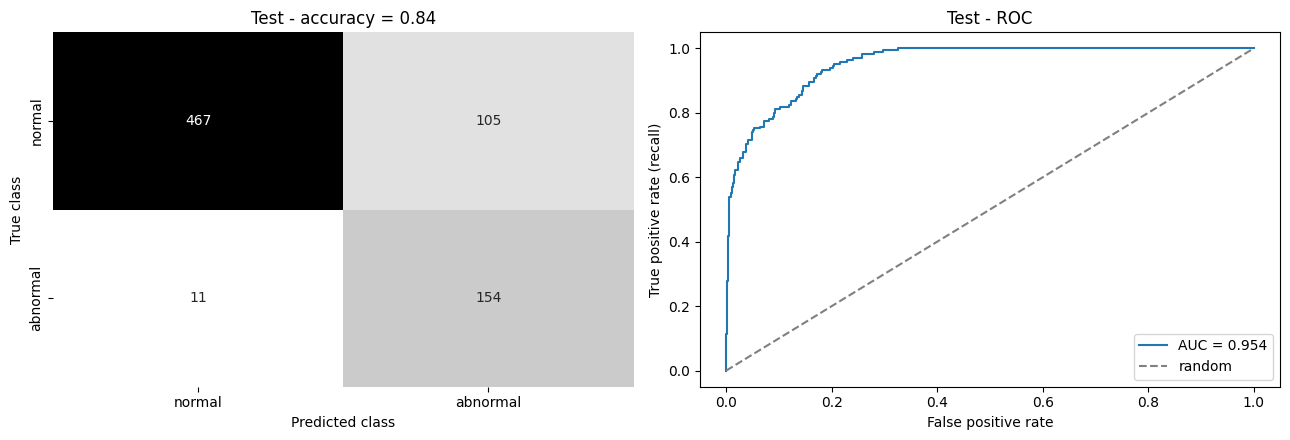

In [6]:
# ==================== TEST: the mean of the probabilities of the final models on the 20% test set ====================
test_probability = mean_probability(members, "test_prob")
test_results = metrics_of(y_test, test_probability)
report = classification_report(y_test, (test_probability > 0.5).astype(int), target_names=["normal", "abnormal"])
print(report)
print({name: round(value, 3) for name, value in test_results.items()})
with open(plots_folder + "tp10_ensemble_test_report.txt", "w") as f:
    f.write("Ensemble (" + " + ".join(members) + ") - test set (" + str(len(y_test)) + " wavs never seen)\n\n" + report)

plt.figure(figsize=(13, 4.5))
plt.subplot(1, 2, 1)
PlotConfusionMatrix(confusion_matrix(y_test, (test_probability > 0.5).astype(int)),
                    "Test - accuracy = {:.2f}".format(test_results["accuracy"]))
plt.subplot(1, 2, 2)
plot_roc(y_test, test_probability, "Test - ROC")
plt.tight_layout()
plt.savefig(plots_folder + "tp10_ensemble_test.png")
plt.show()

In [7]:
# ==================== MLflow ====================
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark_final")
with mlflow.start_run(run_name="ensemble"):
    mlflow.log_param("model", "Ensemble")
    mlflow.log_param("members", ",".join(members))
    mlflow.log_param("features", "soft vote: mean of the probabilities of " + " + ".join(members))
    mlflow.log_param("threshold", 0.5)
    mlflow.log_param("protocol", "out-of-fold probabilities of the 3 folds of the 80% train part (validation), "
                                 "final models on the 20% test set")
    mlflow.log_param("n_train", len(y_train))
    mlflow.log_param("n_test", len(y_test))
    mlflow.set_tag("ensemble", "yes: no model file, the audio engine averages the ONNX outputs of the members")
    for metric in metrics:
        mlflow.log_metric("mean_" + metric, fold_table[metric].mean())
        mlflow.log_metric("test_" + metric, test_results[metric])
    for r in results:
        for metric in metrics:
            mlflow.log_metric("fold" + str(r["fold"]) + "_" + metric, r[metric])
    for fold in [1, 2, 3]:
        mlflow.log_artifact(plots_folder + "tp10_ensemble_val_fold" + str(fold) + ".png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp10_ensemble_val_summary.png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp10_ensemble_test.png", artifact_path="plots/test")
    mlflow.log_artifact(plots_folder + "tp10_ensemble_test_report.txt", artifact_path="plots/test")
print("Ensemble saved in MLflow:", " + ".join(members))

🏃 View run ensemble at: http://localhost:5000/#/experiments/2/runs/7344e5434b734a13aa009d8488552e94
🧪 View experiment at: http://localhost:5000/#/experiments/2


Ensemble saved in MLflow: CNN + ResNet50 + TransformerCNN + DecisionTree
